Working on the numeric clustering

In [1]:
import pandas as pd

In [2]:
# Define the file path
file_path = 'data/European_data_2000.csv'

# Load the dataset
# Note: If you are running the notebook from 'analysis/', 
# the path would just be 'data/European_data_2000.csv'
df = pd.read_csv(file_path)

# 1. See the first 5 rows
print("--- First 5 Rows ---")
display(df.head())

# 2. Check column names, non-null counts, and data types
print("\n--- Data Structure & Types ---")
df.info()

# 3. Summary statistics for numerical columns
print("\n--- Numerical Summary ---")
display(df.describe())

# 4. Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# 5. See the dimensions (rows, columns)
print(f"\nDataset Shape: {df.shape}")

--- First 5 Rows ---


,titleId,imdbUrl,originalTitle,titleType,releaseYear,runtimeMinutes,isAdult,imdbRating,numberOfVotes,allCountries,...,englishTitle,topFiveActors,directors,writers,plotShort,plotMedium,plotLong,genres,keywords,production
0,tt3042384,https://www.imdb.com/title/tt3042384/,Ida,movie,2013.0,82.0,False,7.4,61189.0,"PL, DK, FR, GB",...,Ida,"nm0474492 (Wanda), nm5531398 (Anna), nm4221607...",nm0667734,"nm0667734, nm0501947",A novice nun about to take her vows uncovers a...,"Poland, 1962. Anna, an orphan brought up by nu...",Circa 1962. The movie opens with three noviati...,Drama,"poland, 1960s, jew, novitiate, family secret, ...","Music Box Films, Solopan, Orange Entertainment..."
1,tt2486278,https://www.imdb.com/title/tt2486278/,Blood Shed,movie,2013.0,99.0,False,3.1,689.0,"GB, US",...,Blood Shed,"nm4697835 (Gabriel), nm0000499 (Lucy), nm23560...","nm0368530, nm2350538",nm0368530,A homeless loner moves into a self-storage fac...,Loosely-based on the true events of a homeless...,"Imagine ""people under the stairs"" meeting ""not...","Horror, Thriller","stalker, female nudity, female topless nudity,...","Uncork'd Entertainment, Viva Pictures, Enderby..."
2,tt1361313,https://www.imdb.com/title/tt1361313/,The Extra Man,movie,2010.0,108.0,False,5.8,5470.0,"FR, US",...,The Extra Man,"nm0200452 (Louis Ives), nm0783033 (Vivian Cudl...","nm0075849, nm0700301","nm0700301, nm0024718, nm0024718, nm0075849",A man who escorts wealthy widows in New York's...,"Louis, a young teacher enamored of the age of ...",Louis is a young bookish prep school teacher w...,Comedy,"new york city, brassiere, painting oneself, ca...","Magnolia Pictures, Mares Filmes, BIM Distribuz..."
3,tt0222124,https://www.imdb.com/title/tt0222124/,Se tutte le donne del mondo... (Operazione Par...,movie,1966.0,106.0,False,6.0,434.0,"IT, US",...,Kiss the Girls and Make Them Die,"nm0175528 (Kelly), nm0699063 (Susan Fleming), ...","nm0505610, nm0537985","nm0537985, nm0537985, nm0700474","In this spoof of spy films, CIA agent, Kelly, ...","An outlandish science-fiction, comedy-thriller...","An aging playboy, Mr Ardonian, hatches a plan ...","Action, Comedy","espionage, american agent, female british spy,...","Columbia Pictures, Dear Film, Columbia Picture..."
4,tt0421229,https://www.imdb.com/title/tt0421229/,Mrs Palfrey at the Claremont,movie,2005.0,108.0,False,7.6,4382.0,"GB, US",...,Mrs Palfrey at the Claremont,"nm0687506 (Mrs Palfrey), nm1670029 (Ludo), nm1...",nm0006959,"nm0233026, nm0006959, nm1699869, nm0852331",All but abandoned by her family in a London re...,"Mrs. Palfrey (Dame Joan Plowright), recently w...",The talented indie director Dan Ireland (The W...,"Comedy, Drama","hotel, writer, grandson, friendship, impersona...","Cineville, Westlake Entertainment Group, Parag..."



--- Data Structure & Types ---
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   titleId         2000 non-null   str    
 1   imdbUrl         2000 non-null   str    
 2   originalTitle   2000 non-null   str    
 3   titleType       2000 non-null   str    
 4   releaseYear     2000 non-null   float64
 5   runtimeMinutes  2000 non-null   float64
 6   isAdult         2000 non-null   bool   
 7   imdbRating      2000 non-null   float64
 8   numberOfVotes   2000 non-null   float64
 9   allCountries    2000 non-null   str    
 10  mainCountry     2000 non-null   str    
 11  allLanguages    2000 non-null   str    
 12  firstLanguage   2000 non-null   str    
 13  englishTitle    2000 non-null   str    
 14  topFiveActors   2000 non-null   str    
 15  directors       2000 non-null   str    
 16  writers         2000 non-null   str    
 17  plotShort   

,releaseYear,runtimeMinutes,imdbRating,numberOfVotes
count,2000.000000,2000.000000,2000.000000,2.000000e+03
mean,1997.515500,104.324500,6.386400,5.385845e+04
std,21.796979,20.470777,1.069606,1.284624e+05
min,1913.000000,45.000000,1.500000,1.000000e+01
25%,1981.000000,91.000000,5.800000,2.815250e+03
50%,2006.000000,100.000000,6.500000,1.176900e+04
75%,2014.000000,114.000000,7.100000,4.882325e+04
max,2024.000000,317.000000,9.100000,2.407126e+06



--- Missing Values ---
titleId           0
imdbUrl           0
originalTitle     0
titleType         0
releaseYear       0
runtimeMinutes    0
isAdult           0
imdbRating        0
numberOfVotes     0
allCountries      0
mainCountry       0
allLanguages      0
firstLanguage     0
englishTitle      0
topFiveActors     0
directors         0
writers           0
plotShort         0
plotMedium        0
plotLong          0
genres            0
keywords          0
production        0
dtype: int64

Dataset Shape: (2000, 23)


# Extracting the admissions etc

In [4]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import time

def get_lumiere_admissions(movie_title):
    print(f"Searching for: {movie_title}...")
    
    # --- STEP 1: Search for the movie ---
    search_url = "https://lumiere.obs.coe.int/search"
    
    # NOTE: If the search always returns "Not found", check the Network tab's 
    # "Payload" to see if the key should be 'searchTitle' instead of 'title'.
    search_payload = {
        "title": movie_title 
    }
    
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
    }
    
    try:
        # Make the POST request to the search page
        search_response = requests.post(search_url, data=search_payload, headers=headers)
        search_soup = BeautifulSoup(search_response.text, 'html.parser')
        
        # Find the link to the movie page in the search results
        movie_link_tag = search_soup.find('a', href=re.compile(r'/movie/\d+'))
        
        if not movie_link_tag:
            print("  -> Movie not found in search results.")
            return None
            
        movie_url = "https://lumiere.obs.coe.int" + movie_link_tag['href']
        print(f"  -> Found movie page: {movie_url}")
        
        # --- STEP 2: Scrape the Movie Page ---
        movie_response = requests.get(movie_url, headers=headers)
        movie_soup = BeautifulSoup(movie_response.text, 'html.parser')
        
        # Look for the exact text "EUR OBS:"
        eur_obs_tag = movie_soup.find(string=re.compile("EUR OBS:"))
        
        if eur_obs_tag:
            # The text is inside a <strong> tag, which is inside a <div>
            # We get the parent <div> text (e.g., "EUR OBS: 1 432 184")
            parent_text = eur_obs_tag.parent.parent.text
            
            # Use regex to grab only the digits and remove spaces/text
            admissions_str = re.sub(r'[^\d]', '', parent_text) 
            
            if admissions_str:
                total_admissions = int(admissions_str)
                print(f"  -> Total Admissions: {total_admissions}")
                return total_admissions
            else:
                print("  -> Found 'EUR OBS:' but couldn't parse the number.")
                return None
        else:
            print("  -> 'EUR OBS:' data not found on page.")
            return None
            
    except Exception as e:
        print(f"  -> Error processing '{movie_title}': {e}")
        return None

# --- 3. Execute on the First 10 Movies ---

# Load data (adjust path if needed)
file_path = 'data/European_data_2000.csv'
df = pd.read_csv(file_path)

# Create a small test dataframe (first 10 rows)
test_df = df.head(10).copy()
test_df['total_admissions'] = None

print("--- STARTING EXTRACTION TEST ---")

for index, row in test_df.iterrows():
    title = row['originalTitle']
    
    # Fetch admissions
    admissions = get_lumiere_admissions(title)
    
    # Save back to dataframe
    test_df.at[index, 'total_admissions'] = admissions
    
    # Polite pause
    time.sleep(2) 

print("\n--- TEST COMPLETE ---")

# Display the results
display(test_df[['originalTitle', 'releaseYear', 'total_admissions']])

--- STARTING EXTRACTION TEST ---
Searching for: Ida...
  -> Found movie page: https://lumiere.obs.coe.int/movie/44820
  -> Total Admissions: 1432184
Searching for: Blood Shed...
  -> Found movie page: https://lumiere.obs.coe.int/movie/62117
  -> Total Admissions: 1556
Searching for: The Extra Man...
  -> Found movie page: https://lumiere.obs.coe.int/movie/36773
  -> Total Admissions: 21473
Searching for: Se tutte le donne del mondo... (Operazione Paradiso)...
  -> Movie not found in search results.
Searching for: Mrs Palfrey at the Claremont...
  -> Movie not found in search results.
Searching for: Guest House Paradiso...
  -> Found movie page: https://lumiere.obs.coe.int/movie/12192
  -> Total Admissions: 495531
Searching for: In the Bleak Midwinter...
  -> Found movie page: https://lumiere.obs.coe.int/movie/293
  -> Total Admissions: 213854
Searching for: Rovdyr...
  -> Found movie page: https://lumiere.obs.coe.int/movie/29822
  -> Total Admissions: 73026
Searching for: Sleepless in 

,originalTitle,releaseYear,total_admissions
0,Ida,2013.0,1432184
1,Blood Shed,2013.0,1556
2,The Extra Man,2010.0,21473
3,Se tutte le donne del mondo... (Operazione Par...,1966.0,None
4,Mrs Palfrey at the Claremont,2005.0,None
5,Guest House Paradiso,1999.0,495531
6,In the Bleak Midwinter,1995.0,213854
7,Rovdyr,2008.0,73026
8,Sleepless in New York,2014.0,3220
9,Frankenstein Created Woman,1967.0,None


In [6]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import time
from tqdm import tqdm # The progress bar!

# 1. The Scraping Function (Keep it exactly the same)
def get_lumiere_admissions(movie_title):
    search_url = "https://lumiere.obs.coe.int/search"
    search_payload = {"title": movie_title}
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    
    try:
        search_response = requests.post(search_url, data=search_payload, headers=headers)
        search_soup = BeautifulSoup(search_response.text, 'html.parser')
        movie_link_tag = search_soup.find('a', href=re.compile(r'/movie/\d+'))
        
        if not movie_link_tag:
            return None
            
        movie_url = "https://lumiere.obs.coe.int" + movie_link_tag['href']
        movie_response = requests.get(movie_url, headers=headers)
        movie_soup = BeautifulSoup(movie_response.text, 'html.parser')
        eur_obs_tag = movie_soup.find(string=re.compile("EUR OBS:"))
        
        if eur_obs_tag:
            parent_text = eur_obs_tag.parent.parent.text
            admissions_str = re.sub(r'[^\d]', '', parent_text) 
            if admissions_str:
                return int(admissions_str)
        return None
            
    except Exception as e:
        print(f"Error on {movie_title}: {e}")
        return None

# ==========================================
# 2. LOAD DATA AND SETUP
# ==========================================

file_path = 'data/European_data_2000.csv'
backup_file = 'data/Lumiere_Backup.csv'

# Let's test on the first 35 movies to see the save trigger 3 times
df = pd.read_csv(file_path).head(35).copy()

# Create the column if it doesn't exist yet
if 'total_admissions' not in df.columns:
    df['total_admissions'] = None

print("--- STARTING BATCH EXTRACTION ---")

# ==========================================
# 3. THE SCRAPING LOOP WITH AUTO-SAVE
# ==========================================

# Wrap the iterrows in tqdm() to get a nice progress bar
for index, row in tqdm(df.iterrows(), total=df.shape[0], desc="Scraping Lumiere"):
    title = row['originalTitle']
    
    # RESUME FEATURE: Only scrape if we haven't gotten the data yet!
    if pd.isna(row['total_admissions']):
        
        # Fetch the admissions
        admissions = get_lumiere_admissions(title)
        
        # Update the dataframe
        df.at[index, 'total_admissions'] = admissions
        
        # Be polite to their server
        time.sleep(2)
        
    # AUTO-SAVE FEATURE: Save every 10 iterations
    # Note: index starts at 0, so we use (index + 1)
    if (index + 1) % 10 == 0:
        df.to_csv(backup_file, index=False)
        # Using tqdm.write instead of print so it doesn't break the visual progress bar
        tqdm.write(f"[SAVED] Progress backed up at movie #{index + 1}")

# Final save when the loop completely finishes
df.to_csv(backup_file, index=False)
print(f"\n--- DONE! Final dataset saved to {backup_file} ---")

--- STARTING BATCH EXTRACTION ---


Scraping Lumiere:  29%|██▊       | 10/35 [00:31<01:11,  2.86s/it]

[SAVED] Progress backed up at movie #10


Scraping Lumiere:  57%|█████▋    | 20/35 [01:01<00:43,  2.87s/it]

[SAVED] Progress backed up at movie #20


Scraping Lumiere:  86%|████████▌ | 30/35 [01:31<00:15,  3.05s/it]

[SAVED] Progress backed up at movie #30


Scraping Lumiere: 100%|██████████| 35/35 [01:46<00:00,  3.04s/it]


--- DONE! Final dataset saved to data/Lumiere_Backup.csv ---


In [9]:
import os
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import time
from tqdm import tqdm

# ==========================================
# 1. THE SCRAPING FUNCTION
# ==========================================
def get_lumiere_admissions(movie_title):
    search_url = "https://lumiere.obs.coe.int/search"
    search_payload = {"title": movie_title}
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    
    try:
        search_response = requests.post(search_url, data=search_payload, headers=headers)
        search_soup = BeautifulSoup(search_response.text, 'html.parser')
        movie_link_tag = search_soup.find('a', href=re.compile(r'/movie/\d+'))
        
        if not movie_link_tag:
            return None
            
        movie_url = "https://lumiere.obs.coe.int" + movie_link_tag['href']
        movie_response = requests.get(movie_url, headers=headers)
        movie_soup = BeautifulSoup(movie_response.text, 'html.parser')
        eur_obs_tag = movie_soup.find(string=re.compile("EUR OBS:"))
        
        if eur_obs_tag:
            parent_text = eur_obs_tag.parent.parent.text
            admissions_str = re.sub(r'[^\d]', '', parent_text) 
            if admissions_str:
                return int(admissions_str)
        return None
            
    except Exception as e:
        return None

# ==========================================
# 2. SMART DATA LOADING (RESUME LOGIC)
# ==========================================
original_file = 'data/European_data_2000.csv'

# ---> CHANGED THE BACKUP FILE NAME HERE <---
backup_file = 'data/Lumiere_Full_Backup.csv' 

if os.path.exists(backup_file):
    print(f"--- Found existing backup! Resuming progress from {backup_file} ---")
    df = pd.read_csv(backup_file)
else:
    print(f"--- Starting fresh from {original_file} ---")
    df = pd.read_csv(original_file)
    df['total_admissions'] = None

# ==========================================
# 3. THE FULL SCRAPING LOOP
# ==========================================
for index, row in tqdm(df.iterrows(), total=df.shape[0], desc="Scraping Lumiere"):
    title = row['originalTitle']
    
    if pd.isna(row['total_admissions']):
        
        admissions = get_lumiere_admissions(title)
        df.at[index, 'total_admissions'] = admissions
        
        time.sleep(1)
        
    if (index + 1) % 10 == 0:
        df.to_csv(backup_file, index=False)

df.to_csv(backup_file, index=False)
print(f"\n--- SUCCESS! Final dataset saved to {backup_file} ---")

--- Starting fresh from data/European_data_2000.csv ---


Scraping Lumiere: 100%|██████████| 2000/2000 [1:11:01<00:00,  2.13s/it]



--- SUCCESS! Final dataset saved to data/Lumiere_Full_Backup.csv ---


In [11]:
import pandas as pd

# Define the path to your backup file
backup_file = 'data/Lumiere_Full_Backup.csv'

try:
    # Load the dataset
    df = pd.read_csv(backup_file)
    
    # Convert admissions to numeric (turns "Not Found" into NaN)
    valid_admissions = pd.to_numeric(df['total_admissions'], errors='coerce')
    
    # Count the results
    total_movies = len(df)
    movies_with_data = valid_admissions.notna().sum()
    missing_or_not_found = valid_admissions.isna().sum()
    
    print(f"--- LUMIERE SCRAPING STATS ---")
    print(f"Total movies processed/in dataset: {total_movies}")
    print(f"✅ Movies WITH attendance data: {movies_with_data}")
    print(f"❌ Movies without data (Not Found / Pending): {missing_or_not_found}")
    
    # 1. Preview the successful ones
    print("\n--- Quick Preview of Found Data ---")
    success_df = df[valid_admissions.notna()]
    display(success_df[['originalTitle', 'releaseYear', 'total_admissions']].head())

    # 2. Print the dataset of movies with NO data
    print("\n--- Movies with NO Data (Not Found or Pending) ---")
    missing_df = df[valid_admissions.isna()]
    
    # Display the first 20 movies missing data (remove .head(20) to see all of them)
    display(missing_df[['originalTitle', 'releaseYear', 'total_admissions']].head(20))

except FileNotFoundError:
    print(f"Error: Could not find '{backup_file}'. Make sure your scraping script has successfully run and saved at least once!")

--- LUMIERE SCRAPING STATS ---
Total movies processed/in dataset: 2000
✅ Movies WITH attendance data: 1842
❌ Movies without data (Not Found / Pending): 158

--- Quick Preview of Found Data ---


,originalTitle,releaseYear,total_admissions
0,Ida,2013.0,1432184.0
1,Blood Shed,2013.0,1556.0
2,The Extra Man,2010.0,21473.0
5,Guest House Paradiso,1999.0,495531.0
6,In the Bleak Midwinter,1995.0,213854.0



--- Movies with NO Data (Not Found or Pending) ---


,originalTitle,releaseYear,total_admissions
3,Se tutte le donne del mondo... (Operazione Par...,1966.0,NaN
4,Mrs Palfrey at the Claremont,2005.0,NaN
9,Frankenstein Created Woman,1967.0,NaN
10,Astérix le Gaulois,1967.0,NaN
16,La orgía nocturna de los vampiros,1973.0,NaN
19,Taste the Blood of Dracula,1970.0,NaN
24,The McKenzie Break,1970.0,NaN
63,Believe: The Eddie Izzard Story,2009.0,NaN
79,La casa sperduta nel parco,1980.0,NaN
104,Carry on Loving,1970.0,NaN


The missing seem truly missing

--- REAL-WORLD CENTROIDS (The 'Average' Movie of each Cluster) ---


,runtimeMinutes,imdbRating,numberOfVotes,total_admissions,Movie Count
Cluster 0,93.90,5.63,18287.08,1138447.60,841
Cluster 1,114.41,7.08,60392.29,1432862.23,930
Cluster 2,123.58,7.42,499740.63,22159619.77,71


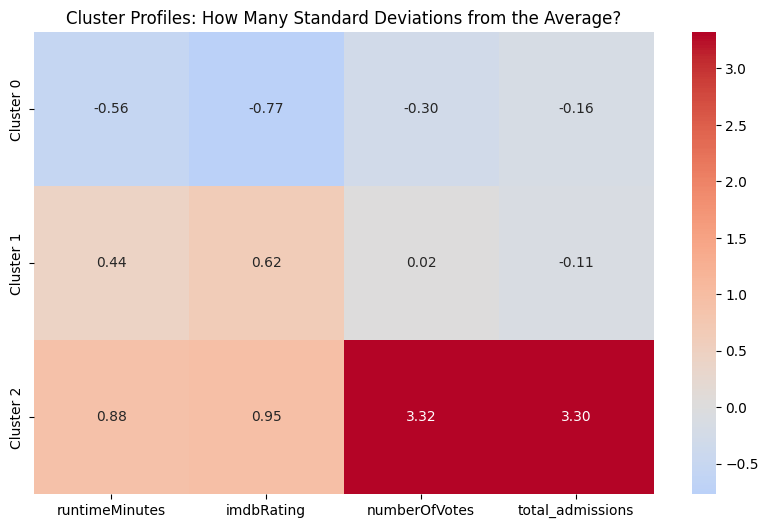


--- Top 5 Most Voted Movies in Cluster 0 ---


,originalTitle,releaseYear,runtimeMinutes,imdbRating,numberOfVotes,total_admissions
786,AVP: Alien vs. Predator,2004.0,101.0,5.7,220409.0,5884967.0
1660,Hansel & Gretel: Witch Hunters,2013.0,88.0,6.1,220046.0,5374374.0
1229,Transporter 2,2005.0,87.0,6.3,218956.0,3384429.0
1634,Resident Evil: Apocalypse,2004.0,94.0,6.1,213623.0,3839062.0
1561,Resident Evil: Extinction,2007.0,94.0,6.2,208797.0,3636124.0



--- Top 5 Most Voted Movies in Cluster 1 ---


,originalTitle,releaseYear,runtimeMinutes,imdbRating,numberOfVotes,total_admissions
1058,In Bruges,2008.0,107.0,7.9,472217.0,2082201.0
1369,Room,2015.0,118.0,8.1,461610.0,1930677.0
709,127 Hours,2010.0,94.0,7.5,408866.0,2787031.0
33,Man on Fire,2004.0,146.0,7.7,398487.0,3356289.0
1281,Jagten,2012.0,115.0,8.3,372398.0,1740536.0



--- Top 5 Most Voted Movies in Cluster 2 ---


,originalTitle,releaseYear,runtimeMinutes,imdbRating,numberOfVotes,total_admissions
1452,Fight Club,1999.0,139.0,8.8,2407126.0,6435231.0
956,Léon,1994.0,110.0,8.5,1280541.0,277743.0
1806,The Shining,1980.0,146.0,8.4,1144494.0,411136.0
1383,Harry Potter and the Deathly Hallows - Part 2,2011.0,130.0,8.1,976358.0,40124774.0
1484,Intouchables,2011.0,112.0,8.5,957603.0,41554200.0


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load and clean the data
file_path = 'data/Lumiere_Full_Backup.csv'
df = pd.read_csv(file_path)
df['total_admissions'] = pd.to_numeric(df['total_admissions'], errors='coerce')

features = ['runtimeMinutes', 'imdbRating', 'numberOfVotes', 'total_admissions']
df_clean = df.dropna(subset=features).copy()

# 2. Scale the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_clean[features])

# 3. Fit K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans.fit_predict(scaled_data)

# ==========================================
# 4. CENTROID ANALYSIS
# ==========================================

# A. Get the Raw Scaled Centroids (Standard Deviations from the Mean)
# This tells us how "far above/below normal" a cluster is for a specific feature.
centroids_scaled = kmeans.cluster_centers_
scaled_centroid_df = pd.DataFrame(centroids_scaled, columns=features)
scaled_centroid_df.index = [f'Cluster {i}' for i in range(3)]

# B. Get the Real-World (Unscaled) Centroids
# This translates those mathematical centers back into actual minutes, ratings, and ticket sales.
centroids_real = scaler.inverse_transform(centroids_scaled)
real_centroid_df = pd.DataFrame(centroids_real, columns=features).round(2)
real_centroid_df.index = [f'Cluster {i}' for i in range(3)]
real_centroid_df['Movie Count'] = df_clean['Cluster'].value_counts().sort_index().values

print("--- REAL-WORLD CENTROIDS (The 'Average' Movie of each Cluster) ---")
display(real_centroid_df)

# ==========================================
# 5. VISUALIZE THE CENTROID PROFILES
# ==========================================

plt.figure(figsize=(10, 6))
# We plot the SCALED centroids as a heatmap. 
# 0 = exactly average. >0 = above average. <0 = below average.
sns.heatmap(scaled_centroid_df, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.title("Cluster Profiles: How Many Standard Deviations from the Average?")
plt.show()

# ==========================================
# 6. EXAMINE THE MOVIES IN EACH CLUSTER
# ==========================================
for i in range(3):
    print(f"\n--- Top 5 Most Voted Movies in Cluster {i} ---")
    sample = df_clean[df_clean['Cluster'] == i].sort_values(by='numberOfVotes', ascending=False).head(5)
    display(sample[['originalTitle', 'releaseYear'] + features])

In [ ]:
import os
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import time
from tqdm import tqdm

# ==========================================
# 1. THE EXCEL SCRAPING FUNCTION
# ==========================================
def get_lumiere_admissions_from_excel(movie_title):
    search_url = "https://lumiere.obs.coe.int/search"
    search_payload = {"title": movie_title}
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    
    try:
        # --- Step A: Search for the movie ID ---
        search_response = requests.post(search_url, data=search_payload, headers=headers)
        search_soup = BeautifulSoup(search_response.text, 'html.parser')
        movie_link_tag = search_soup.find('a', href=re.compile(r'/movie/\d+'))
        
        if not movie_link_tag:
            return "Not Found"
            
        film_id = movie_link_tag['href'].split('/')[-1]
        
        # --- Step B: Download the Excel file ---
        export_url = f"https://lumiere.obs.coe.int/movie/{film_id}/export"
        excel_response = requests.get(export_url, headers=headers)
        
        if excel_response.status_code != 200:
            return "Not Found"
            
        # Read the "Admissions" sheet into pandas directly from memory
        df_admissions = pd.read_excel(excel_response.content, sheet_name='Admissions')
        
        # --- Step C: Find the 'Total since...' column and sum it ---
        total_cols = [col for col in df_admissions.columns if 'Total since' in str(col)]
        
        if total_cols:
            total_col_name = total_cols[0]
            # Convert the column to numeric (ignoring blanks) and sum the entire column
            total_admissions = pd.to_numeric(df_admissions[total_col_name], errors='coerce').sum()
            return int(total_admissions)
        else:
            return "Not Found"

    except Exception as e:
        print(f"Error on '{movie_title}': {e}")
        return "Not Found"

# ==========================================
# 2. SETUP FOR TEST (10 MOVIES)
# ==========================================
original_file = 'data/European_data_2000.csv'
test_backup_file = 'data/Lumiere_Excel_Test.csv'

# Load just the first 10 movies for this test
df = pd.read_csv(original_file).head(10).copy()
df['excel_total_admissions'] = None

print("--- STARTING EXCEL EXTRACTION TEST (10 Movies) ---")

# ==========================================
# 3. THE LOOP
# ==========================================
for index, row in tqdm(df.iterrows(), total=df.shape[0], desc="Scraping via Excel"):
    title = row['originalTitle']
    
    if pd.isna(row['excel_total_admissions']):
        
        # Fetch admissions using the new Excel method
        admissions = get_lumiere_admissions_from_excel(title)
        df.at[index, 'excel_total_admissions'] = admissions
        
        # Polite pause
        time.sleep(2)
        
    # Auto-save every 5 movies just for the sake of the test
    if (index + 1) % 5 == 0:
        df.to_csv(test_backup_file, index=False)

# Final save
df.to_csv(test_backup_file, index=False)

print("\n--- TEST COMPLETE ---")
# Let's see the comparison!
display(df[['originalTitle', 'releaseYear', 'excel_total_admissions']])

FileNotFoundError: [Errno 2] No such file or directory: 'analysis/data/European_data_2000.csv'